# Regional Pacific sea level

Regional counterpart of the National sea-level notebooks. It describes sea-level change across the tropical and subtropical Pacific using monthly CMEMS satellite altimetry, and compares it with the UHSLC tide gauges located inside Pacific EEZs:

1. absolute sea-level trends (mm/yr) with all Pacific EEZ boundaries;
2. relative sea-level trends at tide gauges and their difference from altimetry;
3. regional-mean sea level and five-year anomaly maps;
4. the sea-level response to ENSO;
5. minor-flood days per storm year at all tide gauges.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level.py).')
sys.path.insert(0, str(repo_root / 'functions'))

from data_downloaders import download_oni_index
from sea_level import (
    COMPLETENESS_THRESHOLD, MINOR_FLOOD_THRESHOLD_CM, ONI_URL, get_cmems_monthly_pacific, get_uhslc_metadata,
    pacific_uhslc_stations, process_trend_with_nan, regional_flood_days, regional_station_trends,
    save_dict_json, save_table_to_csv,
)
from sea_level_plotting import (
    plot_pacific_sl_field, plot_regional_change_map_filled_tide_gauges, plot_regional_flood_matrix,
    plot_regional_flood_overview, plot_series_with_trend,
    plot_station_trend_comparison,
)
from sst import PacificSST, plot_pacific_sst_panels

## 1. Configuration

The map window matches the regional SST analysis (125°E–115°W, 35°S–35°N). Tide gauges are kept when they lie inside, or within 0.5° of, one of the Pacific EEZ polygons (coastal gauges often fall just landward of the EEZ baseline).

In [3]:
data_dir = repo_root / 'data'
sea_level_dir = data_dir / 'sea_level'
regional_sl_dir = data_dir / 'regional' / 'sea_level'
eez_file = data_dir / 'regional' / 'Pacific_EEZs' / 'Pacific_EEZs.shp'
fig_dir = repo_root / 'outputs' / 'figures' / 'regional_pacific'
tab_dir = repo_root / 'outputs' / 'tables' / 'regional_pacific'
matrix_dir = repo_root / 'matrix_cc' / 'figures'
for directory in (fig_dir, tab_dir, matrix_dir):
    directory.mkdir(parents=True, exist_ok=True)

pacific_extent = (125, 245, -35, 35)
start, end = '1993-01-01', '2025-12-31'
period_label = '1993–2025'
last_storm_year = 2025            # May 2025 – April 2026
min_valid_fraction = 0.7          # share of valid months required for a station trend
flood_threshold_cm = MINOR_FLOOD_THRESHOLD_CM
force_download = False

## 2. Satellite altimetry

CMEMS `SEALEVEL_GLO_PHY_L4_MY_008_047` monthly mean sea-level anomaly (m, relative to the 1993–2012 mean) is downloaded once for the Pacific window and block-averaged from 0.125° to 0.25° to keep the cache under `data/regional/sea_level/` small. A Copernicus Marine account is required (`copernicusmarine login`).

In [4]:
cmems_file = get_cmems_monthly_pacific(regional_sl_dir, pacific_extent, start, end, coarsen=2, force_download=force_download)
ds = xr.open_dataset(cmems_file).rename({'longitude': 'lon', 'latitude': 'lat'})
sla = ds['sla'].sel(time=slice(start, end)).load()
eez = gpd.read_file(eez_file).to_crs(4326)
pacific = PacificSST(data_raw=ds, data=ds, eez=eez, extent=pacific_extent)
print(f"{sla.sizes['lat']} x {sla.sizes['lon']} cells, {sla.sizes['time']} months "
      f"({str(sla.time.values[0])[:7]} to {str(sla.time.values[-1])[:7]}); {len(eez)} EEZ polygons")

INFO - 2026-11-06T07:36:07Z - Selected dataset version: "202411"


INFO - 2026-11-06T07:36:07Z - Selected dataset part: "default"


WARNING - 2026-11-06T07:36:07Z - Some of your subset selection [125.0, -115.0] for the longitude dimension exceed the dataset coordinates [-179.9375, 179.9375]


280 x 480 cells, 396 months (1993-01 to 2025-12); 29 EEZ polygons


## 3. Absolute sea-level trend

Ordinary least-squares trend of monthly sea level at each grid cell. Per-cell significance is not drawn because ENSO-driven autocorrelation makes the p-values optimistic; read the map as descriptive.

In [5]:
trend_mag, _, rate, p_rate, err_rate = process_trend_with_nan(sla)
change_cm = 100 * trend_mag  # fitted change over the epoch (cm)
epoch_years = (pd.Timestamp(sla.time.values[-1]) - pd.Timestamp(sla.time.values[0])).days / 365.25
rate_mm = 1000 * rate

weights = np.cos(np.deg2rad(sla.lat)).broadcast_like(sla.isel(time=0)).where(sla.isel(time=0).notnull(), 0)
regional_mean = sla.weighted(weights).mean(('lat', 'lon'))
_, _, regional_rate, regional_p, regional_err = process_trend_with_nan(regional_mean)
print(f'Area-weighted ocean mean over the window: {1000 * float(regional_rate):.2f} ± '
      f'{1000 * 1.96 * float(regional_err):.2f} mm/yr ({period_label})')

Area-weighted ocean mean over the window: 3.36 ± 0.09 mm/yr (1993–2025)


## 4. Tide gauges

UHSLC Fast Delivery daily records are downloaded for every station inside (or within 0.5° of) a Pacific EEZ. A station-month is valid when at least 75% of its days are present; a station enters the trend analysis when at least 70% of the months in the period are valid. Altimetry at the nearest ocean grid cell is sampled on exactly the same months.

In [6]:
stations = pacific_uhslc_stations(pacific_extent, start, end)
points = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(((stations['lon'] + 180) % 360) - 180, stations['lat']), crs=4326)
with warnings.catch_warnings():  # distances in degrees are adequate for a 0.5° tolerance
    warnings.simplefilter('ignore')
    in_eez = gpd.sjoin_nearest(points, eez[['Country', 'geometry']].rename(columns={'Country': 'eez'}),
                               how='inner', max_distance=0.5, distance_col='eez_distance_deg')
stations = in_eez.drop(columns=['geometry', 'index_right']).drop_duplicates('uhslc_id').reset_index(drop=True)
print(f'{len(stations)} UHSLC stations inside or within 0.5° of Pacific EEZs')

station_trends, station_monthly = regional_station_trends(
    stations, sla.rename({'lon': 'longitude', 'lat': 'latitude'}), sea_level_dir, start, end,
    COMPLETENESS_THRESHOLD, min_valid_fraction,
)
station_trends = station_trends.merge(stations[['uhslc_id', 'eez']], on='uhslc_id', how='left')
qc = station_trends[station_trends['qc_pass'] == True].copy()
print(f"{len(qc)} stations pass the completeness requirement; "
      f"{int((station_trends['qc_pass'] == False).sum())} are shown as open circles.")

69 UHSLC stations inside or within 0.5° of Pacific EEZs


35 stations pass the completeness requirement; 34 are shown as open circles.


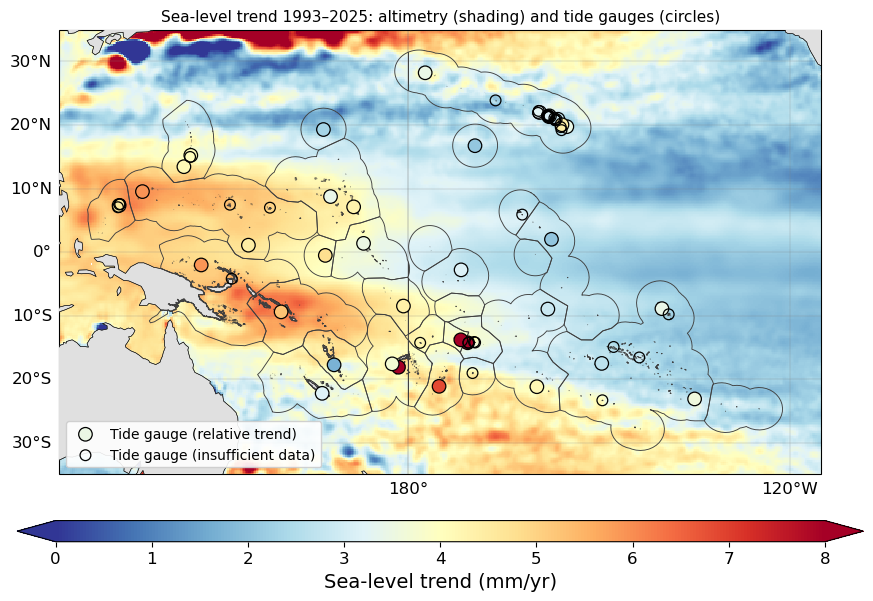

In [7]:
plot_stations = station_trends.assign(tg_plot=station_trends['tg_trend_mm_yr'].where(station_trends['qc_pass'] == True))
fig, ax = plot_pacific_sl_field(
    rate_mm, pacific, f'Sea-level trend {period_label}: altimetry (shading) and tide gauges (circles)',
    cmap='RdYlBu_r', vmin=0, vmax=8, label='Sea-level trend (mm/yr)',
    stations=plot_stations, station_col='tg_plot',
    filename=fig_dir / 'SL_regional_trend_map_pacific.png',
)
fig.savefig(matrix_dir / 'F10_SeaLevel_map_regional_pacific.png', dpi=150, bbox_inches='tight')
plt.show()

### Sea-level change over the epoch, with every tide gauge in the window

PICCM-style version of the map: the background is the fitted absolute change from altimetry over the epoch (cm), and the circles are the relative change at **every** UHSLC tide gauge in the map window (not only those inside Pacific EEZs), computed as the tide-gauge trend × the epoch length. Gauges that do not meet the completeness requirement are drawn as small open circles. The two quantities share a colormap but have separate colour bars and are not merged into a single metric.

97 UHSLC stations in the window; 56 with a relative change.


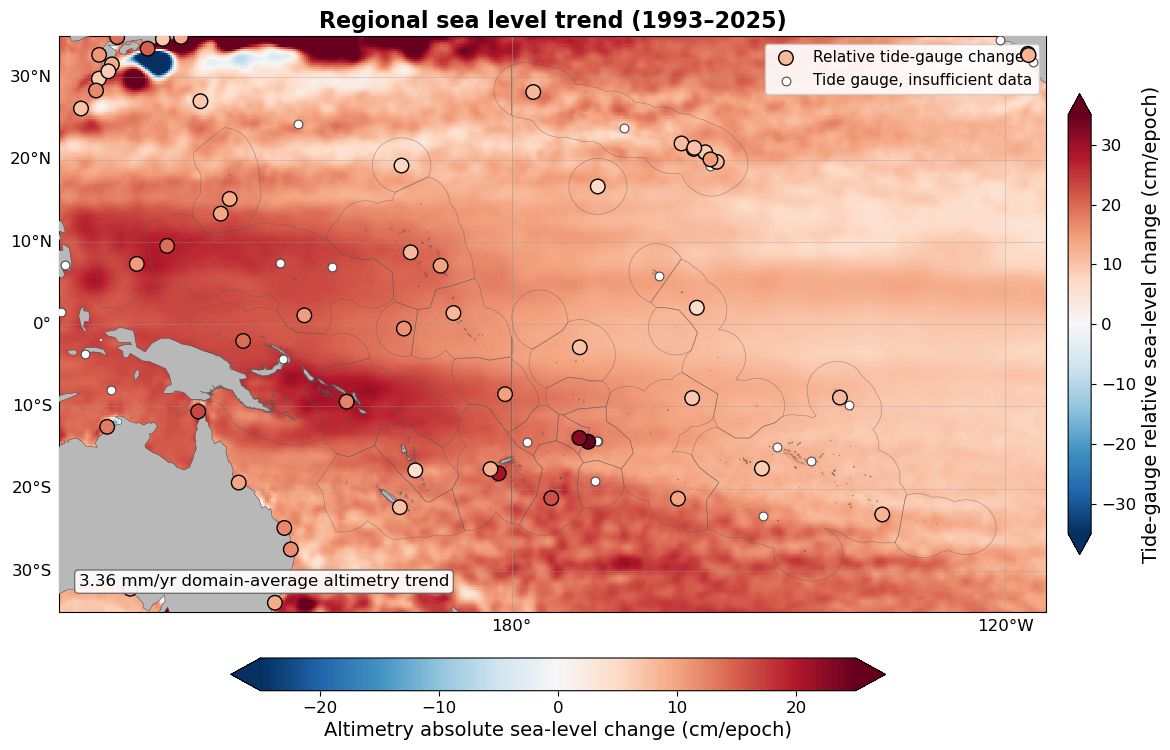

PosixPath('/Users/laurac/Library/Mobile Documents/com~apple~CloudDocs/Projects/CC_indicators/PICCM/CIndRA/outputs/tables/regional_pacific/SL_regional_window_station_changes_pacific.csv')

In [8]:
window_stations = pacific_uhslc_stations(pacific_extent, start, end)
window_trends, _ = regional_station_trends(
    window_stations, sla.rename({'lon': 'longitude', 'lat': 'latitude'}), sea_level_dir, start, end,
    COMPLETENESS_THRESHOLD, min_valid_fraction,
)
window_trends = window_trends.dropna(subset=['lon'])
window_trends['tg_change_cm'] = (window_trends['tg_trend_mm_yr'] * epoch_years / 10).where(window_trends['qc_pass'] == True)
print(f"{len(window_trends)} UHSLC stations in the window; {int(window_trends['tg_change_cm'].notna().sum())} with a relative change.")

fig, ax = plot_regional_change_map_filled_tide_gauges(
    change_cm, pacific, stations=window_trends, station_col='tg_change_cm',
    vmin=-25, vmax=25, station_vmin=-35, station_vmax=35,
    title=f'Regional sea level trend ({period_label})',
    domain_avg_rate_mm_yr=1000 * float(regional_rate),
    filename=fig_dir / 'SL_regional_change_map_tide_gauges_pacific.png',
)
fig.savefig(matrix_dir / 'F10_SeaLevel_change_map_regional_pacific.png', dpi=200, bbox_inches='tight')
plt.show()
save_table_to_csv(window_trends.round(3), tab_dir, 'SL_regional_window_station_changes_pacific.csv')

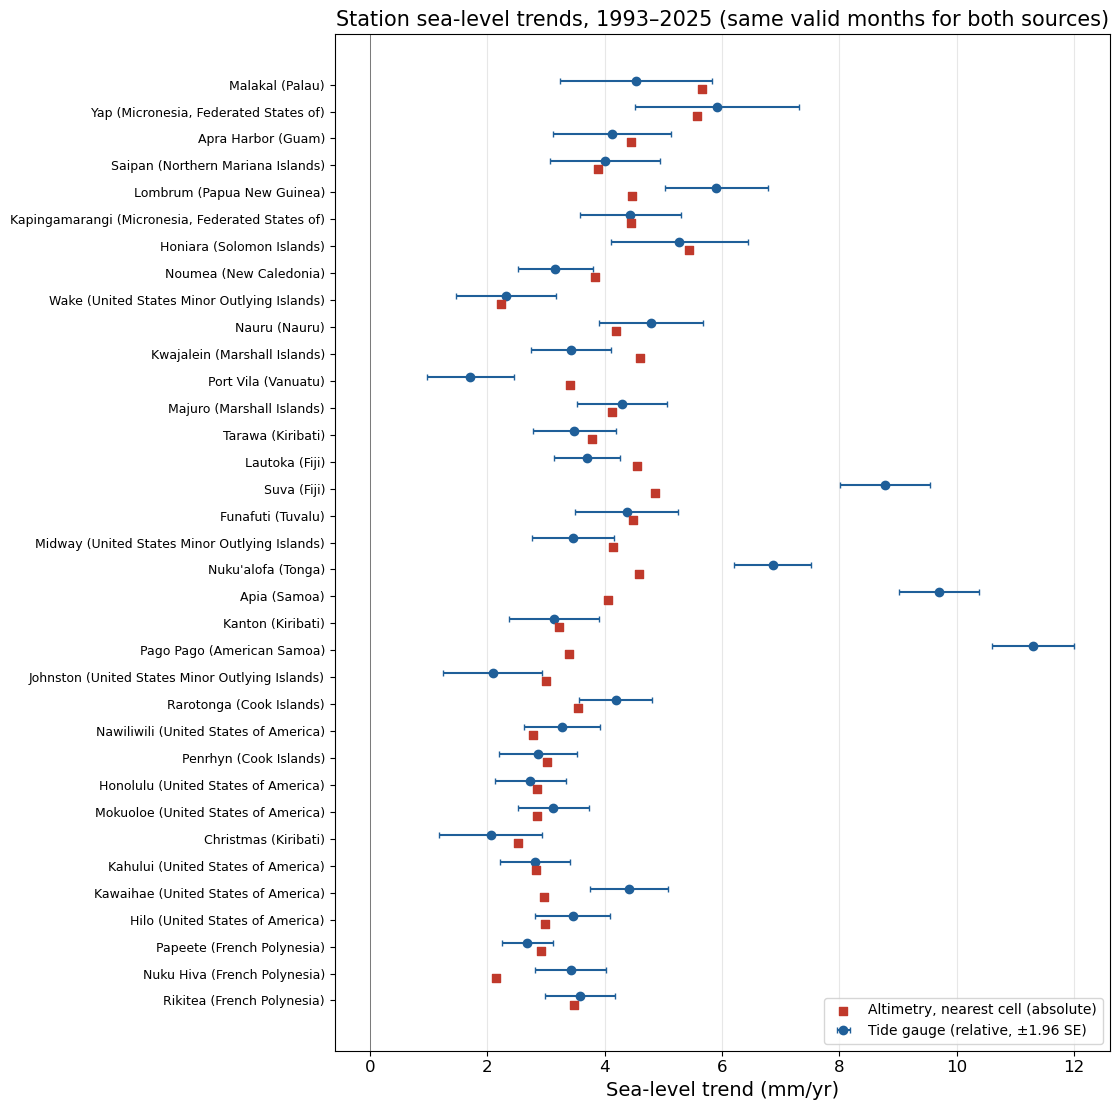

,uhslc_id,name,country,eez,lon,lat,first_valid_month,last_valid_month,valid_fraction,qc_pass,tg_trend_mm_yr,tg_trend_se_mm_yr,alt_trend_mm_yr,alt_minus_tg_mm_yr
31,56,Pago Pago,American Samoa,American Samoa,189.32,-14.28,1993-01,2025-11,0.92,True,11.30,0.36,3.40,-7.91
38,401,Apia,Samoa,Samoa,188.24,-13.82,1993-03,2025-12,0.95,True,9.70,0.35,4.05,-5.65
14,18,Suva,Fiji,Fiji,178.43,-18.13,1998-02,2025-12,0.83,True,8.78,0.39,4.86,-3.92
22,38,Nuku'alofa,Tonga,Tonga,184.82,-21.14,1993-01,2025-12,0.98,True,6.86,0.34,4.59,-2.27
5,8,Yap,"Micronesia, Federated States of",Micronesia,138.12,9.51,1993-01,2025-12,0.85,True,5.92,0.71,5.57,-0.35
37,400,Lombrum,Papua New Guinea,Papua New Guinea,147.38,-2.04,1994-10,2025-11,0.84,True,5.90,0.45,4.46,-1.44
6,9,Honiara,Solomon Islands,Solomon Islands,159.96,-9.42,1994-08,2025-12,0.92,True,5.27,0.59,5.43,0.16
2,4,Nauru,Nauru,Nauru,166.91,-0.53,1993-07,2025-12,0.88,True,4.79,0.45,4.19,-0.59
4,7,Malakal,Palau,Palau,134.45,7.33,1993-01,2025-12,0.98,True,4.53,0.66,5.65,1.12
20,29,Kapingamarangi,"Micronesia, Federated States of",Micronesia,154.81,1.08,1993-01,2025-12,0.72,True,4.44,0.44,4.45,0.02


In [9]:
fig, ax = plot_station_trend_comparison(qc, period_label)
fig.savefig(fig_dir / 'SL_regional_station_trends_pacific.png', dpi=150, bbox_inches='tight')
plt.show()

trend_columns = ['uhslc_id', 'name', 'country', 'eez', 'lon', 'lat', 'first_valid_month', 'last_valid_month',
                 'valid_fraction', 'qc_pass', 'tg_trend_mm_yr', 'tg_trend_se_mm_yr', 'alt_trend_mm_yr',
                 'alt_minus_tg_mm_yr']
station_table = station_trends[trend_columns].round(2)
save_table_to_csv(station_table, tab_dir, 'SL_regional_station_trends_pacific.csv')
station_table[station_table['qc_pass'] == True].sort_values('tg_trend_mm_yr', ascending=False)

Positive `alt_minus_tg_mm_yr` values mean the land is rising relative to the ocean (the gauge records less rise than altimetry); negative values indicate subsidence or local effects that enhance relative sea-level rise.

## 5. Regional mean and five-year anomalies

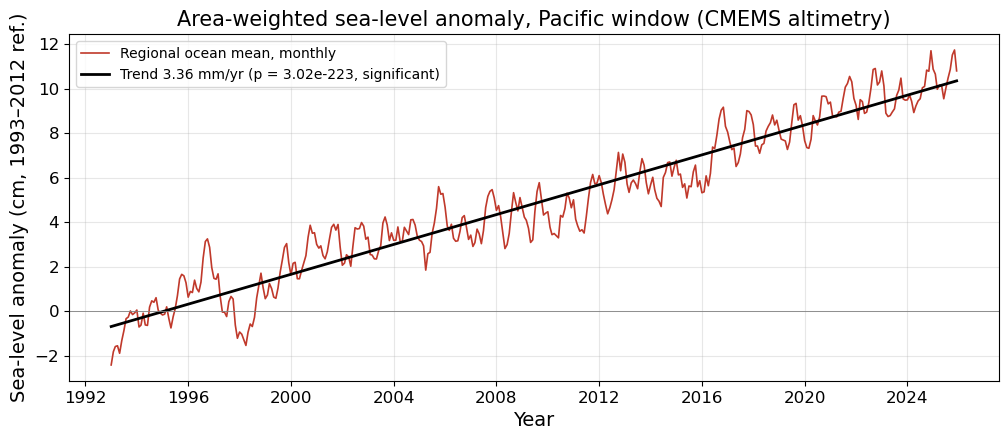

In [10]:
fig, ax, res = plot_series_with_trend(
    100 * regional_mean.to_series(),
    'Area-weighted sea-level anomaly, Pacific window (CMEMS altimetry)',
    ylabel='Sea-level anomaly (cm, 1993–2012 ref.)',
    label='Regional ocean mean, monthly',
)
fig.savefig(fig_dir / 'SL_regional_mean_timeseries_pacific.png', dpi=150, bbox_inches='tight')
fig.savefig(matrix_dir / 'F10_SeaLevel_trends_regional_pacific.png', dpi=150, bbox_inches='tight')
plt.show()

Five-year mean sea-level anomalies relative to the 1993–2012 reference. Unlike the detrended National maps, these fields include the long-term rise, so later periods appear progressively higher.

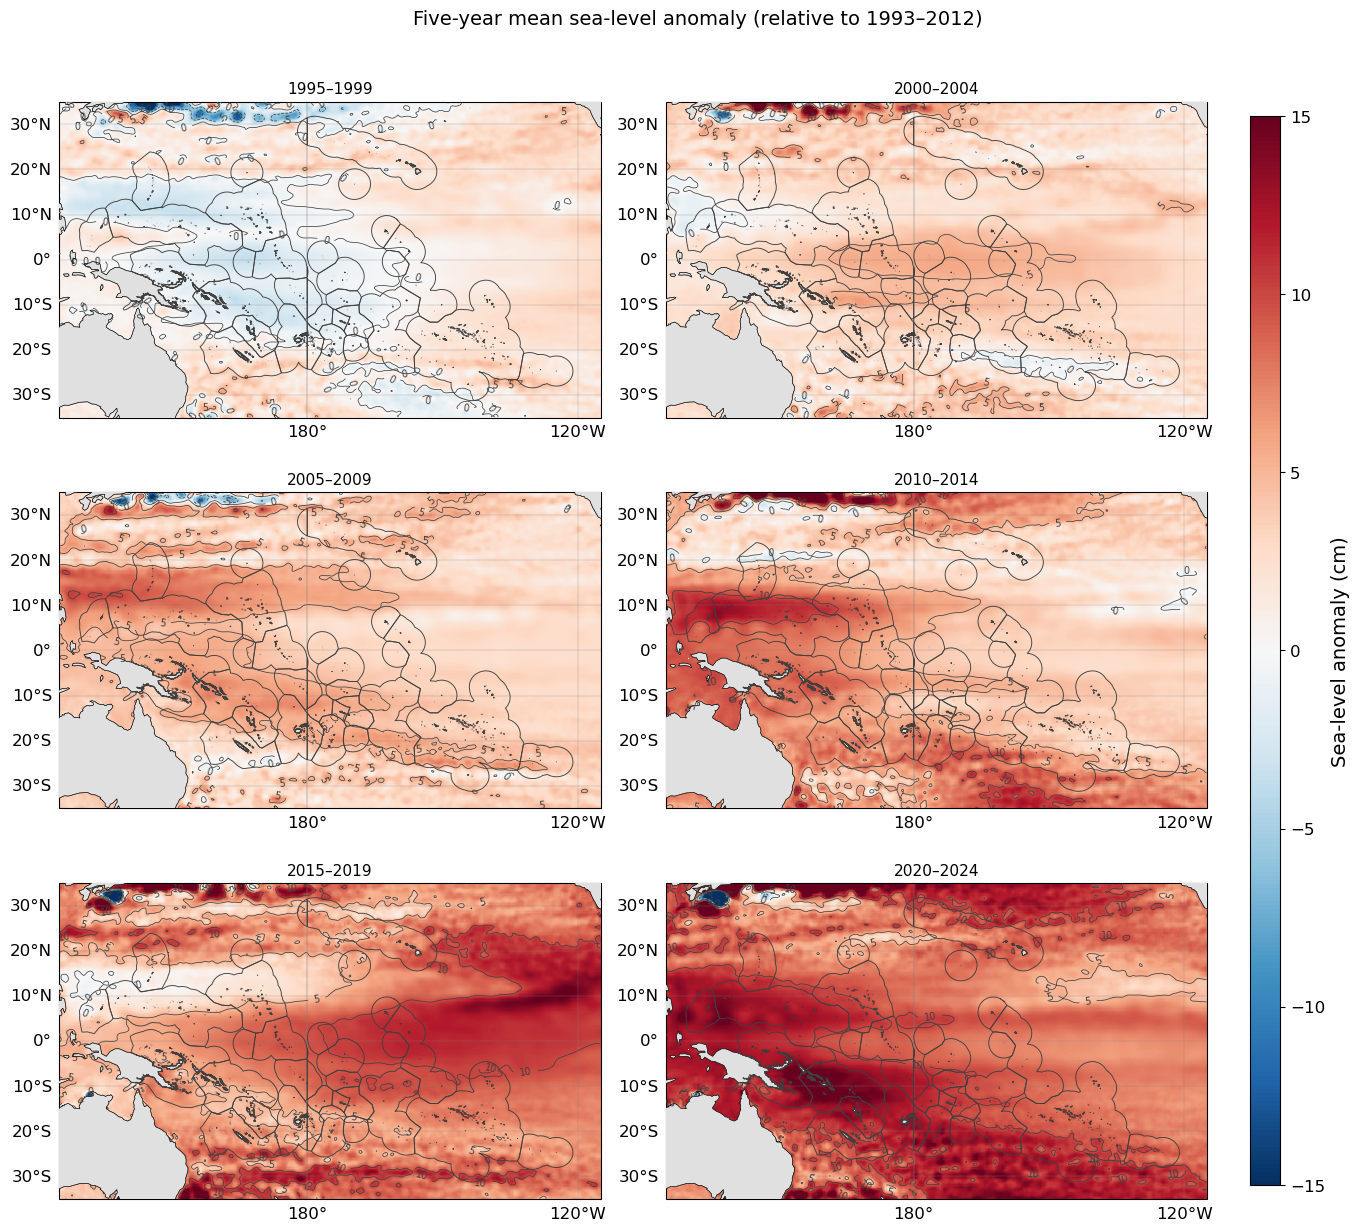

In [11]:
blocks = [(1995, 1999), (2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019), (2020, 2024)]
block_means = xr.concat(
    [100 * sla.sel(time=slice(f'{a}-01-01', f'{b}-12-31')).mean('time') for a, b in blocks],
    dim=pd.Index([f'{a}–{b}' for a, b in blocks], name='period'),
)
fig = plot_pacific_sst_panels(
    block_means, pacific, f'Five-year mean sea-level anomaly (relative to 1993–2012)', dim='period',
    cmap='RdBu_r', vmin=-15, vmax=15, label='Sea-level anomaly (cm)', ncols=2,
    contour_levels=(-10, -5, 0, 5, 10), filename=fig_dir / 'SL_regional_5yr_anomalies_pacific.png',
)
plt.show()

## 6. ENSO response

Monthly sea level is detrended at every cell and its mean seasonal cycle removed; the map shows the regression slope on the ONI (cm per °C). Negative values in the west and positive values in the central-eastern equatorial Pacific reflect the zonal redistribution of warm water during El Niño.

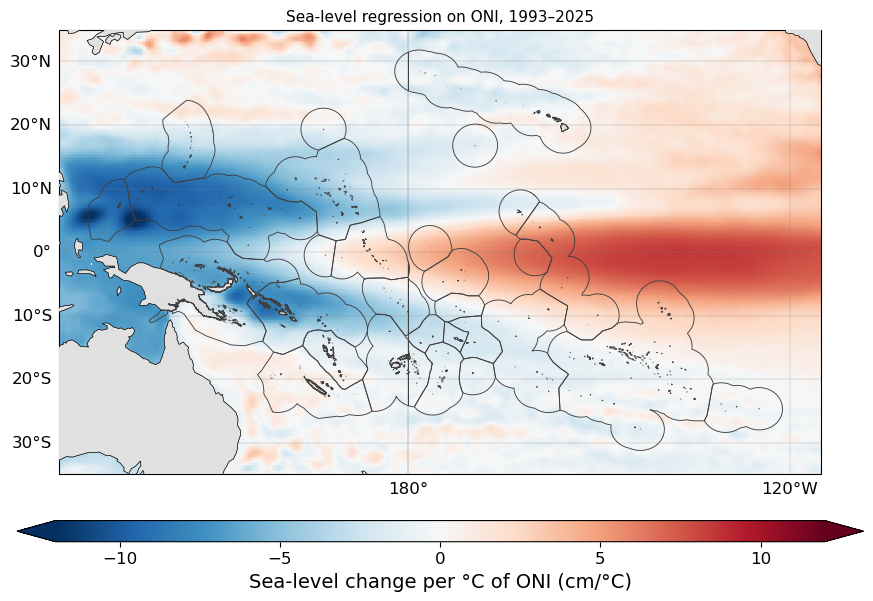

In [12]:
oni = download_oni_index(ONI_URL)
_, sla_trend_line, _, _, _ = process_trend_with_nan(sla)
resid = sla - sla_trend_line
resid = resid.groupby('time.month') - resid.groupby('time.month').mean('time')
oni_m = xr.DataArray(oni['ONI'].reindex(pd.to_datetime(resid.time.values)).values, dims='time', coords={'time': resid.time})
oni_c = oni_m - oni_m.mean()
enso_slope = 100 * ((resid * oni_c).sum('time') / (oni_c ** 2).sum()).where(sla.isel(time=0).notnull())
enso_r = xr.corr(resid, oni_m, dim='time')

fig, ax = plot_pacific_sl_field(
    enso_slope, pacific, f'Sea-level regression on ONI, {period_label}', cmap='RdBu_r',
    vmin=-12, vmax=12, label='Sea-level change per °C of ONI (cm/°C)',
    filename=fig_dir / 'SL_regional_ENSO_regression_pacific.png',
)
plt.show()

## 7. Minor flooding at Pacific tide gauges

Days per storm year with hourly sea level more than 30 cm above the station MHHW, for all stations that passed the completeness requirement. Storm years with less than 75% hourly coverage are grey.

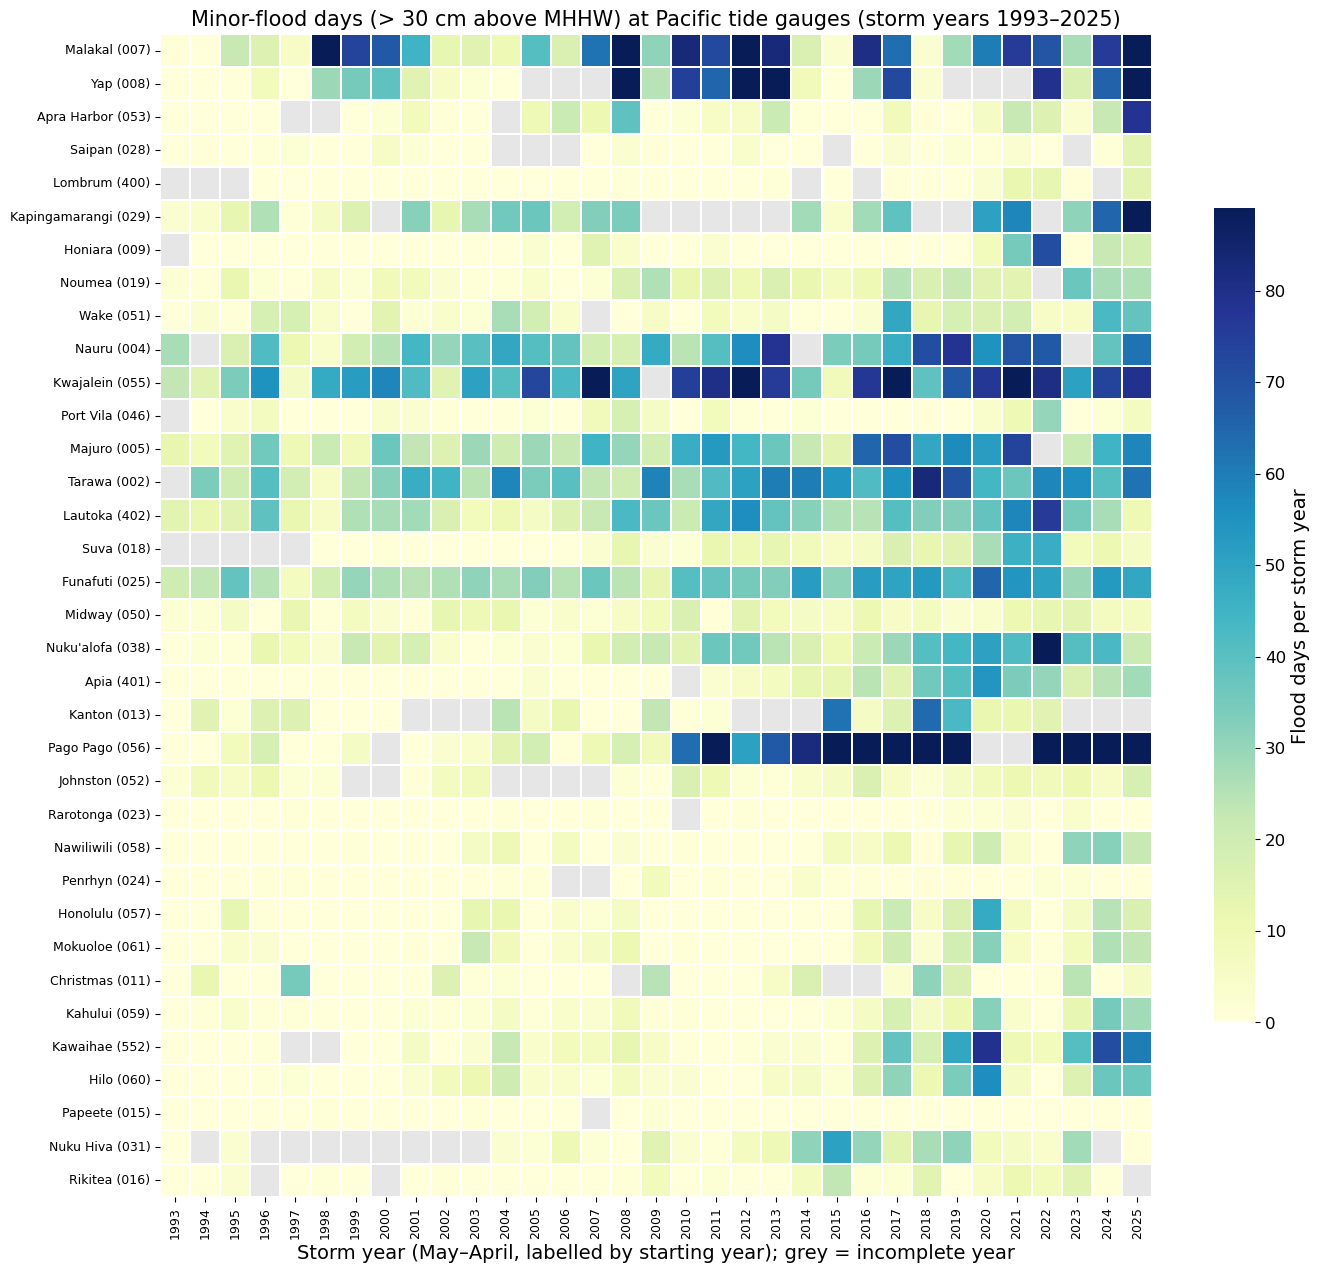

In [13]:
flood_matrix, flood_info = regional_flood_days(
    qc.assign(lon360=qc['lon'] % 360).sort_values('lon360'), sea_level_dir, 1993, last_storm_year, flood_threshold_cm, COMPLETENESS_THRESHOLD,
)
fig, ax = plot_regional_flood_overview(flood_matrix, flood_threshold_cm, f'(storm years 1993–{last_storm_year})')
fig.savefig(fig_dir / 'SL_regional_flood_days_pacific.png', dpi=150, bbox_inches='tight')
fig.savefig(matrix_dir / 'F11_Minor_flood_regional_pacific.png', dpi=150, bbox_inches='tight')
plt.show()

### Station–year flood matrix for long-record tide gauges

Flood days per storm year at a fixed set of long-record UHSLC gauges, ordered north to south, from 1983. Blank cells are storm years with less than 75% hourly coverage. The bars below are aligned with the matrix columns and sum the stations with data in each year, so a missing station lowers that year's total.

The default list reproduces the PICCM station set; Santa Cruz (Galápagos) and Easter Island lie east of the map window but are kept for the eastern-Pacific context. Edit `matrix_station_ids` to change it.

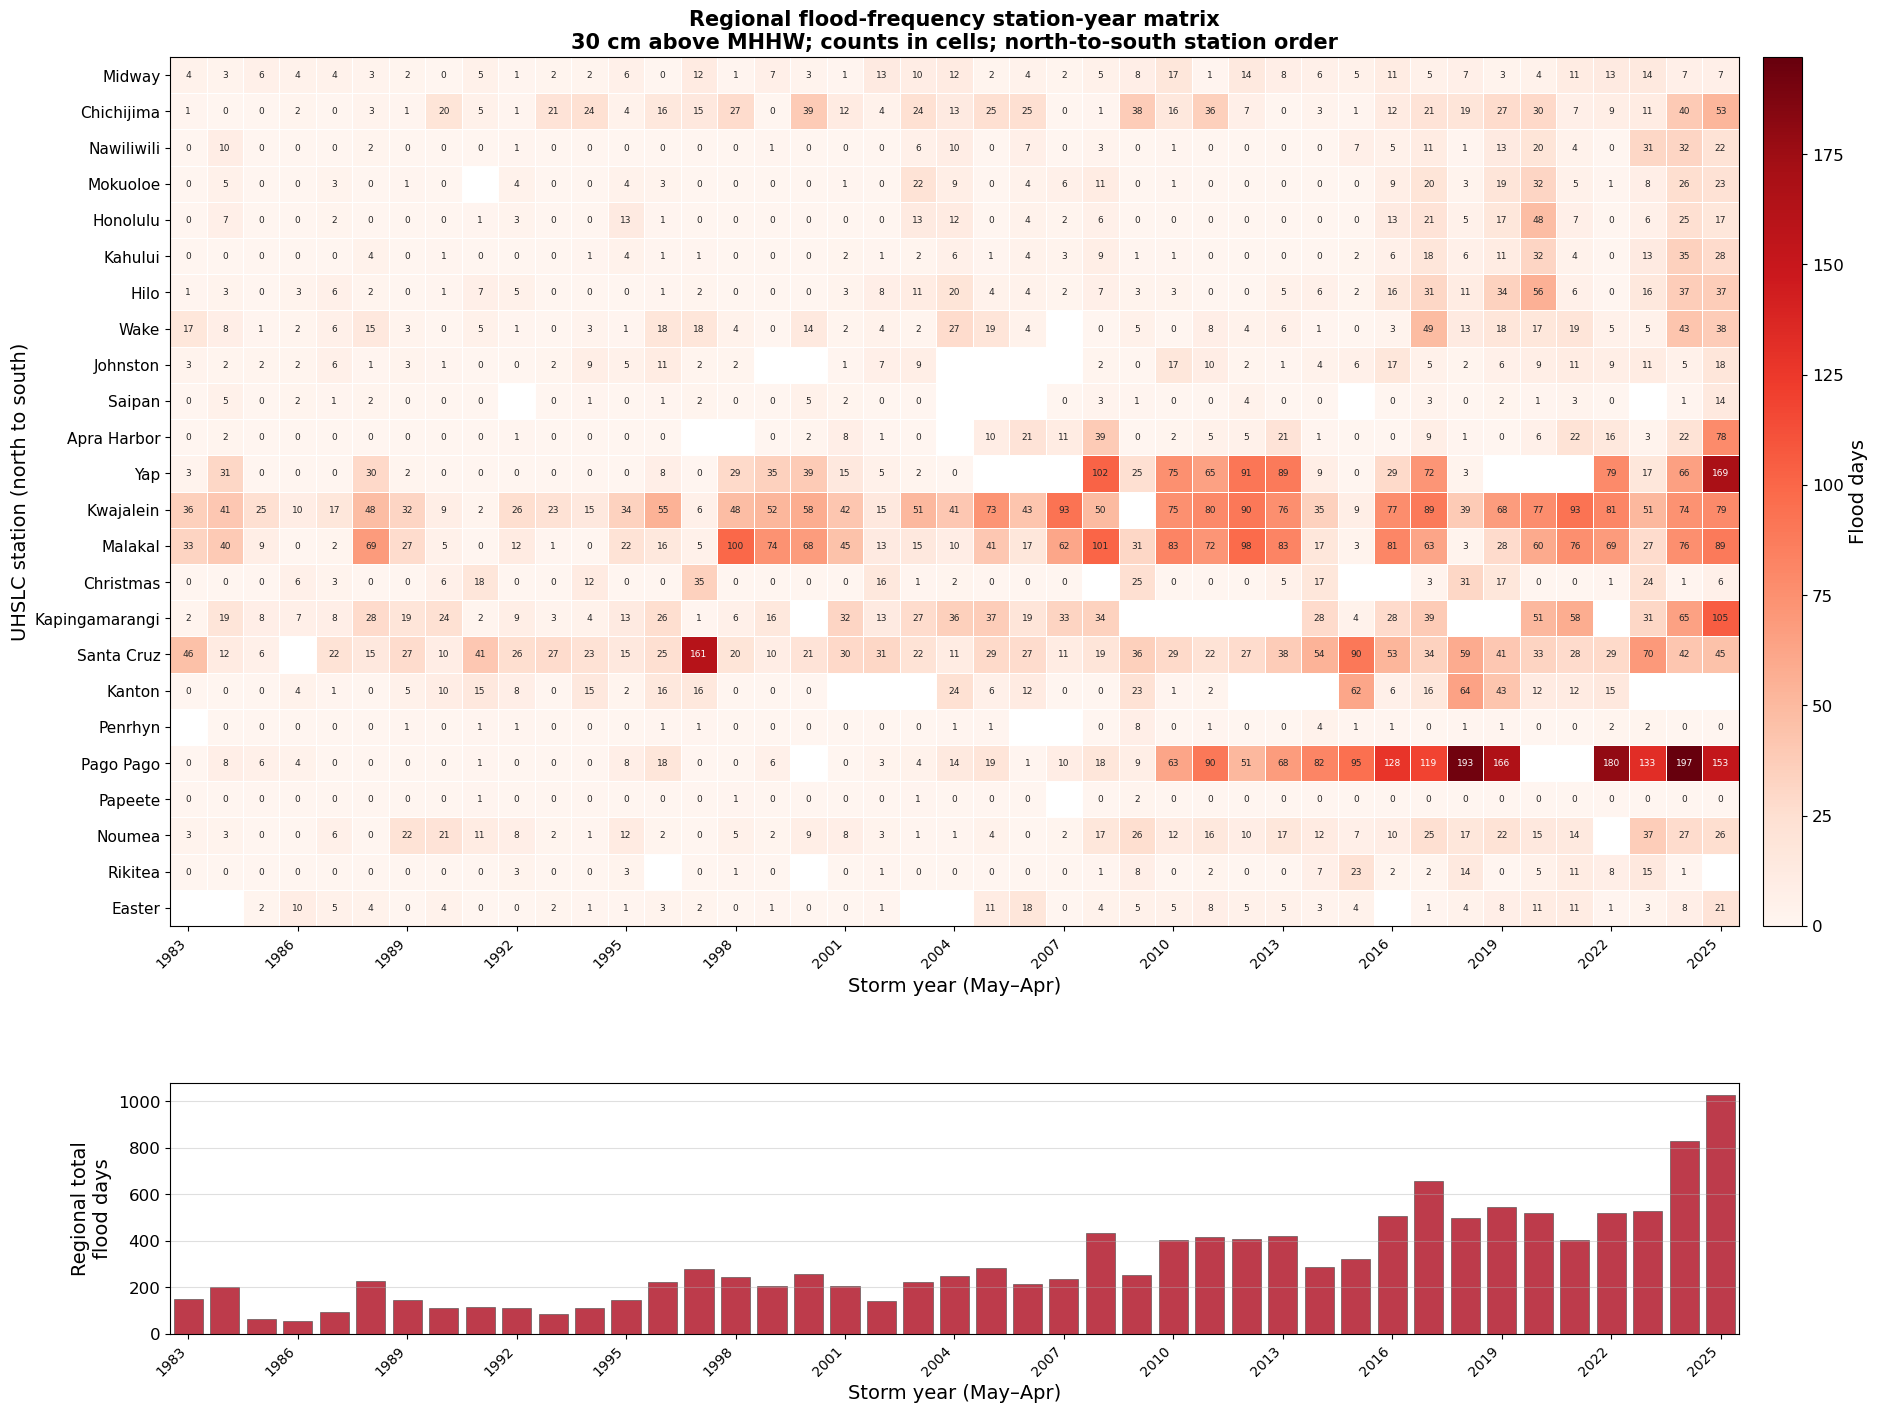

PosixPath('/Users/laurac/Library/Mobile Documents/com~apple~CloudDocs/Projects/CC_indicators/PICCM/CIndRA/outputs/tables/regional_pacific/SL_regional_flood_station_year_matrix_pacific.csv')

In [14]:
matrix_station_ids = [50, 47, 58, 61, 57, 59, 60, 51, 52, 28, 53, 8, 55, 7, 11, 29, 30, 13, 24, 56, 15, 19, 16, 22]
matrix_first_year = 1983

meta = get_uhslc_metadata().set_index('uhslc_id')
matrix_stations = meta.loc[matrix_station_ids].reset_index().sort_values('lat', ascending=False)
station_year_matrix, matrix_info = regional_flood_days(
    matrix_stations, sea_level_dir, matrix_first_year, last_storm_year, flood_threshold_cm, COMPLETENESS_THRESHOLD,
)
station_year_matrix.index = [label.rsplit(' (', 1)[0] for label in station_year_matrix.index]
missing = sorted(set(matrix_stations['name']) - set(station_year_matrix.index))
if missing:
    print('No flood counts for:', missing)

fig, axes = plot_regional_flood_matrix(station_year_matrix, flood_threshold_cm)
fig.savefig(fig_dir / 'SL_regional_flood_station_year_matrix_pacific.png', dpi=200, bbox_inches='tight')
fig.savefig(matrix_dir / 'F11_Minor_flood_station_year_matrix_regional_pacific.png', dpi=200, bbox_inches='tight')
plt.show()
save_table_to_csv(station_year_matrix.rename_axis('station').reset_index(), tab_dir, 'SL_regional_flood_station_year_matrix_pacific.csv')

In [15]:
first = flood_matrix.loc[:, 1993:2002]
last = flood_matrix.loc[:, last_storm_year - 9:last_storm_year]
flood_summary = pd.DataFrame({
    'complete_years': flood_matrix.notna().sum(axis=1),
    'mean_days_1993_2002': first.mean(axis=1).round(1),
    f'mean_days_{last_storm_year - 9}_{last_storm_year}': last.mean(axis=1).round(1),
})
flood_summary['change_days_per_year'] = (flood_summary.iloc[:, 2] - flood_summary['mean_days_1993_2002']).round(1)
flood_summary.index.name = 'station'
save_table_to_csv(flood_matrix.reset_index().rename(columns={'index': 'station'}), tab_dir, 'SL_regional_flood_days_pacific.csv')
save_table_to_csv(flood_summary.reset_index(), tab_dir, 'SL_regional_flood_summary_pacific.csv')
errors = flood_info[flood_info['error'].notna()] if 'error' in flood_info else pd.DataFrame()
if len(errors):
    print('Stations without flood counts:')
    display(errors)
flood_summary.sort_values('change_days_per_year', ascending=False)

,complete_years,mean_days_1993_2002,mean_days_2016_2025,change_days_per_year
station,,,,
Pago Pago (056),30,3.9,158.6,154.7
Yap (008),27,13.1,62.1,49.0
Kapingamarangi (029),24,12.7,53.9,41.2
Kawaihae (552),31,0.9,39.0,38.1
Kwajalein (055),32,34.8,72.8,38.0
Majuro (005),32,18.8,54.7,35.9
Nuku'alofa (038),33,8.4,42.3,33.9
Nauru (004),30,24.3,58.1,33.8
Apia (401),32,0.0,30.4,30.4


## 8. Summary metrics

In [16]:
regional_metrics = {
    'period': period_label,
    'extent': list(pacific_extent),
    'altimetry_regional_mean_trend_mm_yr': 1000 * float(regional_rate),
    'altimetry_regional_mean_trend_se_mm_yr': 1000 * float(regional_err),
    'stations_inside_eez': int(len(station_trends)),
    'stations_qc_pass': int(len(qc)),
    'median_tide_gauge_trend_mm_yr': float(qc['tg_trend_mm_yr'].median()),
    'median_altimetry_trend_at_gauges_mm_yr': float(qc['alt_trend_mm_yr'].median()),
    'median_alt_minus_tg_mm_yr': float(qc['alt_minus_tg_mm_yr'].median()),
    'flood_threshold_cm_above_mhhw': flood_threshold_cm,
    f'median_change_flood_days_{last_storm_year - 9}_{last_storm_year}_vs_1993_2002': float(flood_summary['change_days_per_year'].median()),
}
save_dict_json(regional_metrics, tab_dir, 'SL_regional_summary_metrics_pacific.json')
pd.Series(regional_metrics).to_frame('value')

,value
period,1993–2025
extent,"[125, 245, -35, 35]"
altimetry_regional_mean_trend_mm_yr,3.357245
altimetry_regional_mean_trend_se_mm_yr,0.048305
stations_inside_eez,69
stations_qc_pass,35
median_tide_gauge_trend_mm_yr,3.585227
median_altimetry_trend_at_gauges_mm_yr,3.778584
median_alt_minus_tg_mm_yr,0.015162
flood_threshold_cm_above_mhhw,30


## Interpretation and reproducibility notes

- **Sources:** CMEMS L4 DUACS monthly altimetry (absolute sea level, 0.25° after block averaging) and UHSLC Fast Delivery tide gauges (relative sea level, level-1 QC only).
- **Spatial scope:** the regional mean is an area-weighted average of every ocean cell in the map window, not of the EEZs; tide-gauge values are point measurements.
- **Trends** are ordinary least-squares fits over 1993–2025; ENSO variability is large in the western Pacific, so rates over ~30 years carry substantial uncertainty and the per-cell significance is not shown.
- **Altimetry vs tide gauges:** both trends use the same valid months; their difference approximates vertical land motion plus representativeness error near the coast.
- **Flooding:** the 30 cm above MHHW threshold is a regional proxy for minor flooding; local impact thresholds differ. Storm years with incomplete hourly data are excluded.
- **Data volume:** the first run downloads ~200 MB of altimetry and the daily and hourly records of every station; later runs reuse the caches.